# Getting Started with Dynare.jl: A Linear New Keynesian (NK) Example

This notebook walks through how to use **Dynare** from Julia (the `Dynare.jl` package) to solve a macroeconomic model written in a `.mod` file, and how to inspect the key fields stored in the result object (`context`) one by one.

As a running example we use a small linear New Keynesian (NK) model with a Zero Lower Bound (ZLB) on the nominal interest rate, contained in `linear_nk.mod`. This is the code used in Chapter 1 of [*Theory and Practice of Monetary Policy: A Dynamic Macroeconomic Approach*](https://sites.google.com/view/nakata-monetary-policy-nippyo) (Nakata, Nippyo; in Japanese) and can be downloaded from the book's companion site.

## What is Dynare?

**Dynare** is a software platform for the numerical analysis and estimation of macroeconomic models, including DSGE models. It originally runs on top of MATLAB / Octave.

**Dynare.jl** is its Julia implementation: it reads `.mod` files (written in Dynare's domain-specific modeling language) directly and lets you solve the model entirely within Julia.

Main advantages:
- No MATLAB license required
- Easy integration with the Julia ecosystem (`Plots.jl`, `DataFrames.jl`, etc.)
- Existing `.mod` files written for MATLAB Dynare work almost as-is

## Setup: Loading Packages

Install the packages with `Pkg.add` on first use (uncomment the `Pkg.add` line below and run it once).

In [2]:
# using Pkg
# Pkg.add(["Dynare", "Plots"])

using Dynare
using Plots

## Structure of a `.mod` File

A `.mod` file is a Dynare-specific model file, made up of the following main blocks:

| Block | Purpose |
|---|---|
| `var` | Declares endogenous variables |
| `varexo` | Declares exogenous shocks |
| `parameters` | Declares parameters and assigns their values |
| `model; ... end;` | Writes the model equations |
| `initval; ... end;` | Initial values used when computing the steady state |
| `shocks; ... end;` | Sets the size and timing of shocks |
| `perfect_foresight_setup` / `perfect_foresight_solver` | Chooses the solver (here, deterministic simulation) |

Let's print the contents of the actual `linear_nk.mod` file.

In [3]:
print(read("linear_nk.mod", String))

//
// addpath c:/dynare/4.6.1/matlab
// dynare linear_nk
//
var y pi i ni rn;
varexo e e_rn;
parameters cBETA cSIGMA cKAPPA cALPHA1 cALPHA2 cRELB cRSTAR cPhiPi cRhoR shock_size;

cBETA = 1/(1+0.005);
cSIGMA = 1;
cKAPPA = (6-1)/500*(1+1);
cALPHA1= 0;
cALPHA2= 0;
cRELB  = 0;
cRSTAR = 1-cBETA;
cPhiPi = 2;
cRhoR  = 0.0;
shock_size = -0.0225;

%shock_size = -0.01;

model;

y  = (1-cALPHA1)*y(1) - cSIGMA*(i - pi(1) - rn);
pi = cKAPPA*y + (1-cALPHA2)*cBETA*pi(1) + e;
ni = cRSTAR + cRhoR*(ni(-1)-cRSTAR) + (1.0-cRhoR)*cPhiPi*pi;
//0  = -ni + rn + cRhoR*(ni(-1)-cRSTAR) + (1.0-cRhoR)*cPhiPi*pi;
i  =  max(ni,cRELB);
rn = cRSTAR + 0.85*(rn(-1) - cRSTAR) + e_rn*shock_size;

end;

initval;

y  = 0;
pi = 0;
i  = cRSTAR;
rn = cRSTAR;
ni = cRSTAR;
e     = 0;
e_rn  = 0;

end;

steady;

shocks;
var e_rn;
periods 1;
values 1;
end;

perfect_foresight_setup(periods=100);
perfect_foresight_solver;


## Running the Model

Passing the path of a `.mod` file to the `@dynare` macro triggers the following steps all at once:

1. Parses the `.mod` file
2. Generates Julia code for the model
3. Computes the steady state
4. Runs the solver declared inside the `.mod` file (here, `perfect_foresight_solver`)

The return value is a `context` object, which holds all information and results related to the model.

In [4]:
context = @dynare "linear_nk.mod";

Dynare version: 0.10.4
2026-05-17T13:32:36.370: Starting @dynare linear_nk.mod
["linear_nk.mod", "language=julia", "json=compute", "notmpterms"]
Dynare preprocessor version: 7.0.0+0


Starting preprocessing of the model file ...
Found 5 equation(s).
Evaluating expressions...
Computing static model derivatives (order 1).
Normalizing the static model...
Finding the optimal block decomposition of the static model...
2 block(s) found:
  1 recursive block(s) and 1 simultaneous block(s).
  the largest simultaneous block has 4 equation(s)
                                 and 4 feedback variable(s).
Computing dynamic model derivatives (order 1).
Normalizing the dynamic model...
Finding the optimal block decomposition of the dynamic model...
2 block(s) found:
  1 recursive block(s) and 1 simultaneous block(s).
  the largest simultaneous block has 4 equation(s)
                                 and 3 feedback variable(s).
JSON written after Computing step.
Preprocessing completed.


2026-05-17T13:32:36.554: End of preprocessing
2026-05-17T13:32:36.584: Start parse_statements!


  Steady state

────┬───────
 y  │  0.0
 pi │   0.0
  i │ 0.005
 ni │ 0.005
 rn │ 0.005
────┴───────

2026-05-17T13:32:40.990: End parse_statements!
2026-05-17T13:32:40.991: End parser


## Exploring the `context` Object

The `context` object stores the model's structural information, parameters, steady state, solution, simulation results, and more. We'll walk through the main fields in order.

First, let's use `propertynames` to see what top-level fields are available.

In [5]:
propertynames(context)

(:symboltable, :models, :modfileinfo, :results, :timings, :work, :workspaces)

### 1. `context.symboltable`

Holds a list of every symbol that appears in the model (endogenous variables, exogenous shocks, and parameters) together with their internal index and type. Think of it as the *mapping from variable name to position in arrays*.

In [6]:
context.symboltable

longname: e
texname: e
symboltype: Exogenous
orderintype: 1
longname: cKAPPA
texname: cKAPPA
symboltype: Parameter
orderintype: 3
longname: cALPHA1
texname: cALPHA1
symboltype: Parameter
orderintype: 4
longname: rn
texname: rn
symboltype: Endogenous
orderintype: 5
longname: shock_size
texname: shock\_size
symboltype: Parameter
orderintype: 10
longname: i
texname: i
symboltype: Endogenous
orderintype: 3
longname: y
texname: y
symboltype: Endogenous
orderintype: 1
longname: cALPHA2
texname: cALPHA2
symboltype: Parameter
orderintype: 5
longname: cRSTAR
texname: cRSTAR
symboltype: Parameter
orderintype: 7
longname: cPhiPi
texname: cPhiPi
symboltype: Parameter
orderintype: 8
longname: cRhoR
texname: cRhoR
symboltype: Parameter
orderintype: 9
longname: cSIGMA
texname: cSIGMA
symboltype: Parameter
orderintype: 2
longname: e_rn
texname: e\_rn
symboltype: Exogenous
orderintype: 2
longname: pi
texname: pi
symboltype: Endogenous
orderintype: 2
longname: cBETA
texname: cBETA
symboltype: Parameter


Dict{String, DynareSymbol} with 17 entries:
  "e"          => 
  "cKAPPA"     => 
  "cALPHA1"    => 
  "rn"         => 
  "shock_size" => 
  "i"          => 
  "y"          => 
  "cALPHA2"    => 
  "cRSTAR"     => 
  "cPhiPi"     => 
  "cRhoR"      => 
  "cSIGMA"     => 
  "e_rn"       => 
  "pi"         => 
  "cBETA"      => 
  "ni"         => 
  "cRELB"      => 

To look up a specific symbol, access the table by name as a dictionary.

In [7]:
context.symboltable["cRELB"]

longname: cRELB
texname: cRELB
symboltype: Parameter
orderintype: 6


### 2. Parameter Values `context.work.params`

A numeric vector of the parameters declared in the `.mod` file. Using the index (`orderintype`) obtained from `symboltable`, you can read or update the value of any particular parameter.

In [8]:
context.work.params

10-element Vector{Float64}:
  0.9950248756218907
  1.0
  0.02
  0.0
  0.0
  0.0
  0.004975124378109319
  2.0
  0.0
 -0.0225

In [9]:
# Example: read the value of cRELB
idx = context.symboltable["cRELB"].orderintype
context.work.params[idx]

0.0

### 3. Model Metadata `context.models[1]`

An object holding meta-information about the model's structure: number of endogenous variables, number of exogenous variables, maximum lag/lead, and so on.

In [10]:
propertynames(context.models[1])

(:endogenous_nbr, :exogenous_nbr, :lagged_exogenous_nbr, :exogenous_deterministic_nbr, :parameter_nbr, :original_endogenous_nbr, :lead_lag_incidence, :n_static, :n_fwrd, :n_bkwrd, :n_both, :n_states, :DErows1, :DErows2, :n_dyn, :i_static, :i_dyn, :i_bkwrd, :i_bkwrd_b, :i_bkwrd_ns, :i_fwrd, :i_fwrd_b, :i_fwrd_ns, :i_both, :i_non_states, :p_static, :p_bkwrd, :p_bkwrd_b, :p_fwrd, :p_fwrd_b, :p_both_b, :p_both_f, :i_current, :p_current, :n_current, :i_current_ns, :p_current_ns, :n_current_ns, :icolsD, :jcolsD, :icolsE, :jcolsE, :colsUD, :colsUE, :i_cur_fwrd, :n_cur_fwrd, :p_cur_fwrd, :i_cur_bkwrd, :n_cur_bkwrd, :p_cur_bkwrd, :i_cur_both, :n_cur_both, :p_cur_both, :gx_rows, :hx_rows, :i_current_exogenous, :i_lagged_exogenous, :serially_correlated_exogenous, :Sigma_e, :maximum_endo_lag, :maximum_endo_lead, :maximum_exo_lag, :maximum_exo_lead, :maximum_exo_det_lag, :maximum_exo_det_lead, :maximum_lag, :maximum_lead, :orig_maximum_endo_lag, :orig_maximum_endo_lead, :orig_maximum_exo_lag, :orig

In [11]:
m = context.models[1]
(endogenous_nbr = m.endogenous_nbr,
 exogenous_nbr  = m.exogenous_nbr,
 maximum_lag    = m.maximum_lag,
 maximum_lead   = m.maximum_lead)

(endogenous_nbr = 5, exogenous_nbr = 2, maximum_lag = 1, maximum_lead = 1)

### 4. Result Object `context.results.model_results[1]`

All computed results live under `context.results.model_results[1]`. The container is an array to allow for handling multiple models at once, but in normal usage taking the first element with `[1]` is sufficient.

Again, let's use `propertynames` to see which result fields are available.

In [12]:
propertynames(context.results.model_results[1])

(:irfs, :trends, :stationary_variables, :estimation, :filter, :forecast, :initial_smoother, :linearrationalexpectations, :simulations, :smoother, :solution_derivatives, :sparsegrids)

### 5. Steady State `... .trends.endogenous_steady_state`

The values of the endogenous variables at the model's steady state. For a linear model, these serve as the "center" around which simulations move.

In [13]:
context.results.model_results[1].trends.endogenous_steady_state

5-element Vector{Float64}:
 0.0
 0.0
 0.004975124378109319
 0.004975124378109319
 0.004975124378109319

### 6. Simulation Results `... .simulations`

Every time you call a solver such as `perfect_foresight_solver`, the result is **appended** to the `simulations` vector.

Right now the solver has only been called once (inside `@dynare`), so the length should be 1.

In [14]:
sims = context.results.model_results[1].simulations
length(sims)

1

### 7. Time-Series Data for a Single Simulation `sim.data`

Each `Simulation` object stores the actual time series in its `data` field, in `AxisArrayTable` format (similar to a DataFrame).

In [15]:
sim = sims[1]
sim.data[1:10, :]

┌───┬────────────┬─────────────┬────────────┬──────────────┬─────────────┬──────
│   │          y │          pi │          i │           ni │          rn │   e ⋯
├───┼────────────┼─────────────┼────────────┼──────────────┼─────────────┼──────
│ 0 │        0.0 │         0.0 │ 0.00497512 │   0.00497512 │  0.00497512 │ 0.0 ⋯
│ 1 │  -0.136332 │  -0.0134102 │        0.0 │   -0.0218452 │  -0.0175249 │ 0.0 ⋯
│ 2 │  -0.108071 │  -0.0107369 │        0.0 │   -0.0164987 │  -0.0141499 │ 0.0 ⋯
│ 3 │ -0.0853022 │  -0.0086184 │        0.0 │   -0.0122617 │  -0.0112811 │ 0.0 ⋯
│ 4 │ -0.0670742 │ -0.00694692 │        0.0 │  -0.00891871 │ -0.00884269 │ 0.0 ⋯
│ 5 │ -0.0525981 │ -0.00563346 │        0.0 │  -0.00629179 │ -0.00677002 │ 0.0 ⋯
│ 6 │ -0.0412236 │ -0.00460441 │        0.0 │  -0.00423369 │ -0.00500825 │ 0.0 ⋯
│ 7 │ -0.0324166 │ -0.00379883 │        0.0 │  -0.00262254 │ -0.00351074 │ 0.0 ⋯
│ 8 │ -0.0257396 │ -0.00316625 │        0.0 │  -0.00135738 │ -0.00223786 │ 0.0 ⋯
│ 9 │  -0.020837 │ -0.002664

### 8. Accessing Individual Variables

`AxisArrayTable` lets you access each column by variable name as a property, just like a DataFrame.

In [16]:
sim.data.y[1:10]    # first 10 periods of the output gap y

┌───┬────────────┐
│   │          y │
├───┼────────────┤
│ 0 │        0.0 │
│ 1 │  -0.136332 │
│ 2 │  -0.108071 │
│ 3 │ -0.0853022 │
│ 4 │ -0.0670742 │
│ 5 │ -0.0525981 │
│ 6 │ -0.0412236 │
│ 7 │ -0.0324166 │
│ 8 │ -0.0257396 │
│ 9 │  -0.020837 │
└───┴────────────┘


In [17]:
sim.data.pi[1:10]   # inflation rate pi

┌───┬─────────────┐
│   │          pi │
├───┼─────────────┤
│ 0 │         0.0 │
│ 1 │  -0.0134102 │
│ 2 │  -0.0107369 │
│ 3 │  -0.0086184 │
│ 4 │ -0.00694692 │
│ 5 │ -0.00563346 │
│ 6 │ -0.00460441 │
│ 7 │ -0.00379883 │
│ 8 │ -0.00316625 │
│ 9 │ -0.00266472 │
└───┴─────────────┘


## Re-simulating after Changing a Parameter

Next, let's change `cRELB` (the level of the ZLB) to a very small value (effectively switching the ZLB off) and compare the response to a world without the ZLB.

To do so, we define a small helper function `set_param!` that updates a parameter by symbol name.

In [18]:
function set_param!(ctx, name::String, value::Float64)
    ctx.work.params[ctx.symboltable[name].orderintype] = value
end

set_param! (generic function with 1 method)

In [19]:
# Effectively disable the ZLB
set_param!(context, "cRELB", -1e6)

# Re-solve the same model
Dynare.perfect_foresight!(; context = context, periods = 100);

After re-solving, the new result is **appended** to the `simulations` vector. The latest result can be retrieved with `sims[end]`.

In [20]:
sims = context.results.model_results[1].simulations
length(sims)

2

In [21]:
zlb_data   = sims[1].data[1:20, :];     # the original ZLB case
nozlb_data = sims[end].data[1:20, :];   # the most recent no-ZLB case

## Plotting the Results

Compare the two scenarios, with and without the ZLB.

- Output gap `y` is shown in % (×100)
- Inflation rate `pi` is shown in annualized % (×400)
- Policy rate `i` is also shown in annualized % (×400)

The number of labels is different than the number of variables to be plotted
The number of labels is different than the number of variables to be plotted


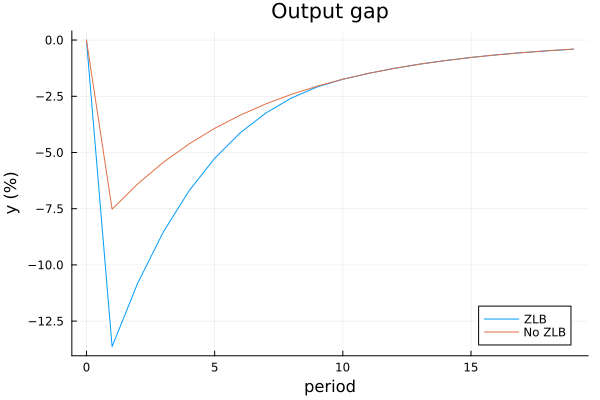

In [22]:
datasets = [("ZLB", zlb_data), ("No ZLB", nozlb_data)]

p = plot(xlabel = "period", ylabel = "y (%)", title = "Output gap")
for (name, d) in datasets
    plot!(p, d.y .* 100, label = name)
end
p

The number of labels is different than the number of variables to be plotted
The number of labels is different than the number of variables to be plotted


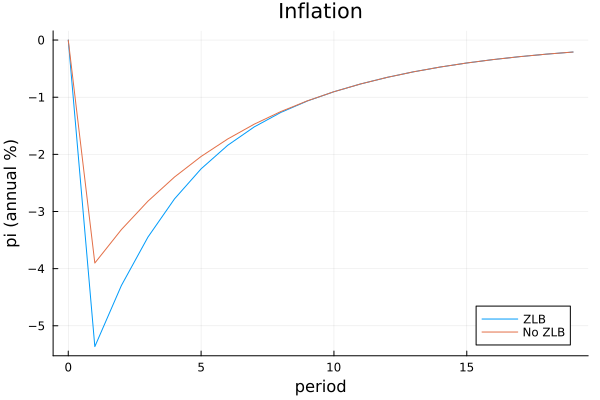

In [23]:
p = plot(xlabel = "period", ylabel = "pi (annual %)", title = "Inflation")
for (name, d) in datasets
    plot!(p, d.pi .* 400, label = name)
end
p

The number of labels is different than the number of variables to be plotted
The number of labels is different than the number of variables to be plotted


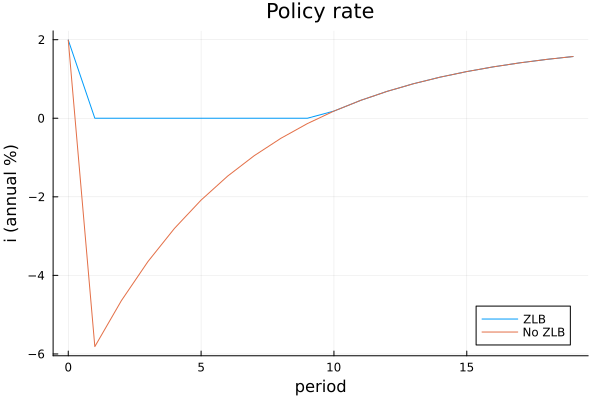

In [24]:
p = plot(xlabel = "period", ylabel = "i (annual %)", title = "Policy rate")
for (name, d) in datasets
    plot!(p, d.i .* 400, label = name)
end
p

## Summary

The basic Dynare.jl workflow shown in this notebook:

1. **Load and solve**: `@dynare "file.mod"` loads the model and runs the solver declared in the `.mod` file in one step
2. **Inspect results**: through the `context` object, access symbols (`symboltable`), parameters (`work.params`), the steady state (`trends.endogenous_steady_state`), and simulation results (`results.model_results[1].simulations`)
3. **Change a parameter**: use the `set_param!` helper to update values and `Dynare.perfect_foresight!` to re-solve (results keep accumulating in `simulations`)
4. **Extract time series**: get an `AxisArrayTable` via `sims[end].data` and access columns with `.y`, `.pi`, etc.

Official Dynare.jl repository: <https://git.dynare.org/Dynare/Dynare.jl>